# Seoul Link Speed EDA Report

강수량, 경사도, 도로등급, 첨두시간대가 링크 평균속도에 미치는 영향을 탐색합니다.

**모델링(`12_derived_features_lightgbm.ipynb`)과는 독립된 분석입니다** — 모델의 gain 기여도는 "다른 피처들과 경쟁했을 때의 상대적 기여도"라 함께 있는 피처에 따라 크게 달라집니다(예: 강수 관련 피처는 이웃속도 피처가 이미 정보 대부분을 흡수해서 gain이 0에 가깝게 나왔습니다). 이 노트북은 그런 모델 구성과 무관하게, 각 요인과 속도의 **원본 관계**(그룹평균·상관계수)를 직접 봅니다 — 빅데이터 분석 보고서의 "요인별 영향력" 섹션에 바로 쓸 수 있는 형태입니다.

**입력(스키마 이관, 이번 갱신)**: `seoul_link_dimension.csv`(링크당 1행, 도로속성·경사도) + `seoul_link_speed_fact.csv`(링크x날짜x시간, 속도·강수) — `LINK_ID`로 결합. 예전 단일 병합 파일(`seoul_link_speed_dem_weather_merged.csv`)은 삭제됐습니다. T-data 전용이었던 `첨두시구분(T1/T2/T3)` 컬럼은 우리 데이터에 없어서, `시간코드-1`(실제시각) 기준으로 오전첨두(7~9시)/오후첨두(17~19시)/비첨두 3단계로 다시 만듭니다.

**주의**: 이 결과는 인과관계 검증이 아니라 탐색적 분석입니다. 최종 해석에서는 시간대, 도로등급, 제한속도, 링크별 특성을 함께 통제해야 합니다.

In [1]:
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Jupyter 실행 위치가 notebooks/ 폴더라고 가정합니다 (jupyter lab/notebook 기본 동작).
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
DOCS_FIGURES_DIR = PROJECT_ROOT / "docs" / "figures" / "eda"
DOCS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

DIMENSION_PATH = PROCESSED_DATA_DIR / "seoul_link_dimension.csv"
FACT_PATH = PROCESSED_DATA_DIR / "seoul_link_speed_fact.csv"

# macOS는 AppleGothic, Windows는 Malgun Gothic으로 한글 폰트 자동 선택
plt.rcParams["font.family"] = "AppleGothic" if platform.system() == "Darwin" else "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLORS = {
    "no_rain": "#4C78A8",
    "rain": "#E45756",
    "bar": "#59A14F",
    "line": "#2F4B7C",
}

In [2]:
dim_cols = ["LINK_ID", "ROAD_RANK", "MAX_SPD", "LENGTH", "slope_pct", "abs_slope_pct", "elev_mean_m", "elev_delta_m"]
dimension = pd.read_csv(DIMENSION_PATH, dtype={"LINK_ID": str, "ROAD_RANK": str}, usecols=dim_cols, encoding="utf-8-sig")
for c in ["MAX_SPD", "LENGTH", "slope_pct", "abs_slope_pct", "elev_mean_m", "elev_delta_m"]:
    dimension[c] = pd.to_numeric(dimension[c], errors="coerce")

fact = pd.read_csv(
    FACT_PATH, dtype={"LINK_ID": str}, encoding="utf-8-sig",
    usecols=["LINK_ID", "시간코드", "평균속도", "precip_mm"],
)
fact["평균속도"] = pd.to_numeric(fact["평균속도"], errors="coerce")
fact["precip_mm"] = pd.to_numeric(fact["precip_mm"], errors="coerce")

df = fact.merge(dimension, on="LINK_ID", how="left", validate="many_to_one")
df = df.dropna(subset=["평균속도", "precip_mm", "abs_slope_pct"])

# 실제 시각 = 시간코드 - 1 (pipeline/02 CREATHM 시+1 규칙, 12번 노트북과 동일 기준)
actual_hour = df["시간코드"].astype(int) - 1
df["peak_period"] = np.select(
    [actual_hour.isin([7, 8, 9]), actual_hour.isin([17, 18, 19])],
    ["T1", "T3"],
    default="N",
)  # T-data의 T1(오전첨두)/T3(오후첨두)/N(비첨두)과 이름을 맞춤 — T2(낮)는 우리 쪽엔 없어 만들지 않음

df["rain_flag"] = np.where(df["precip_mm"] > 0, "rain", "no_rain")
df["rain_bin"] = pd.cut(
    df["precip_mm"],
    bins=[-0.001, 0, 1, 5, 10, np.inf],
    labels=["0mm", "0-1mm", "1-5mm", "5-10mm", "10mm+"],
    include_lowest=True,
)
df["abs_slope_bin"] = pd.cut(
    df["abs_slope_pct"],
    bins=[-0.001, 1, 3, 5, 10, np.inf],
    labels=["0-1%", "1-3%", "3-5%", "5-10%", "10%+"],
    include_lowest=True,
)
df["slope_direction"] = pd.cut(
    df["slope_pct"],
    bins=[-np.inf, -1, 1, np.inf],
    labels=["downhill", "flat", "uphill"],
)
df["slope_risk"] = np.where(df["abs_slope_pct"] >= 5, "steep", "not_steep")
df["rain_slope_group"] = df["rain_flag"] + " + " + df["slope_risk"]

print("행 수:", len(df))
df.head()

행 수: 15094335


,LINK_ID,시간코드,평균속도,precip_mm,ROAD_RANK,MAX_SPD,LENGTH,elev_mean_m,elev_delta_m,slope_pct,abs_slope_pct,peak_period,rain_flag,rain_bin,abs_slope_bin,slope_direction,slope_risk,rain_slope_group
0,1000000301,1.0,13.166667,0.0,103,50,45.892773,29.623407,0.0,0.0,0.0,N,no_rain,0mm,0-1%,flat,not_steep,no_rain + not_steep
1,1000000301,2.0,16.250000,0.0,103,50,45.892773,29.623407,0.0,0.0,0.0,N,no_rain,0mm,0-1%,flat,not_steep,no_rain + not_steep
2,1000000301,3.0,14.000000,0.0,103,50,45.892773,29.623407,0.0,0.0,0.0,N,no_rain,0mm,0-1%,flat,not_steep,no_rain + not_steep
3,1000000301,4.0,15.000000,0.0,103,50,45.892773,29.623407,0.0,0.0,0.0,N,no_rain,0mm,0-1%,flat,not_steep,no_rain + not_steep
4,1000000301,5.0,15.250000,0.0,103,50,45.892773,29.623407,0.0,0.0,0.0,N,no_rain,0mm,0-1%,flat,not_steep,no_rain + not_steep


In [3]:
def summarize(grouped) -> pd.DataFrame:
    return (
        grouped["평균속도"]
        .agg(row_count="count", mean_speed="mean", median_speed="median", std_speed="std")
        .reset_index()
        .assign(
            mean_speed=lambda d: d["mean_speed"].round(2),
            median_speed=lambda d: d["median_speed"].round(2),
            std_speed=lambda d: d["std_speed"].round(2),
        )
    )


def add_labels(ax, fmt="{:.1f}", dy=0.25):
    for patch in ax.patches:
        height = patch.get_height()
        if pd.isna(height):
            continue
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            height + dy,
            fmt.format(height),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
        )


def finish(fig, ax, out_name: str, ylim_pad=0.16):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)
    ax.set_axisbelow(True)
    top = ax.get_ylim()[1]
    ax.set_ylim(0, top * (1 + ylim_pad))
    fig.tight_layout()
    fig.savefig(DOCS_FIGURES_DIR / out_name, dpi=220, bbox_inches="tight")
    plt.show()
    print("저장:", DOCS_FIGURES_DIR / out_name)

## 1. 강수 여부별 평균속도

In [4]:
speed_by_rain_flag = summarize(df.groupby("rain_flag", observed=True))
speed_by_rain_flag

,rain_flag,row_count,mean_speed,median_speed,std_speed
0,no_rain,11536235,22.82,20.06,12.32
1,rain,3558100,22.84,20.29,12.03


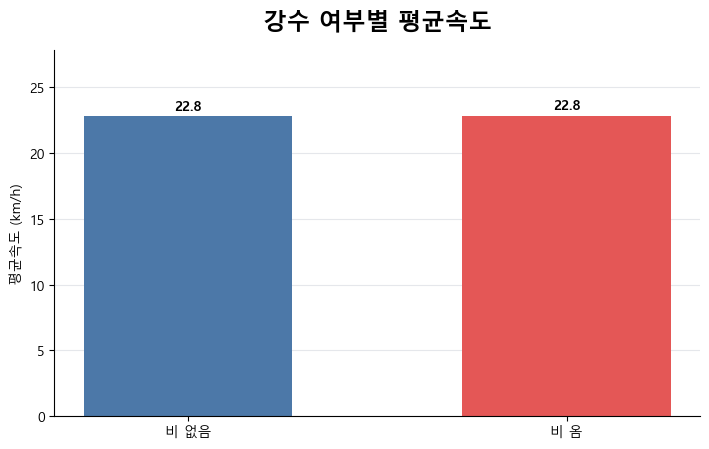

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\01_rain_flag_speed.png


In [5]:
order = ["no_rain", "rain"]
plot_df = speed_by_rain_flag.set_index("rain_flag").loc[order].reset_index()

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.bar(["비 없음", "비 옴"], plot_df["mean_speed"], color=[COLORS["no_rain"], COLORS["rain"]], width=0.55)
ax.set_title("강수 여부별 평균속도", fontsize=17, fontweight="bold", pad=16)
ax.set_ylabel("평균속도 (km/h)")
add_labels(ax)
finish(fig, ax, "01_rain_flag_speed.png")

## 2. 강수량 구간별 평균속도

In [6]:
speed_by_rain_bin = summarize(df.groupby("rain_bin", observed=True))
speed_by_rain_bin

,rain_bin,row_count,mean_speed,median_speed,std_speed
0,0mm,11536235,22.82,20.06,12.32
1,0-1mm,99634,23.31,20.75,12.23
2,1-5mm,216994,23.58,20.75,12.56
3,5-10mm,359972,23.39,20.67,12.46
4,10mm+,2881500,22.70,20.17,11.92


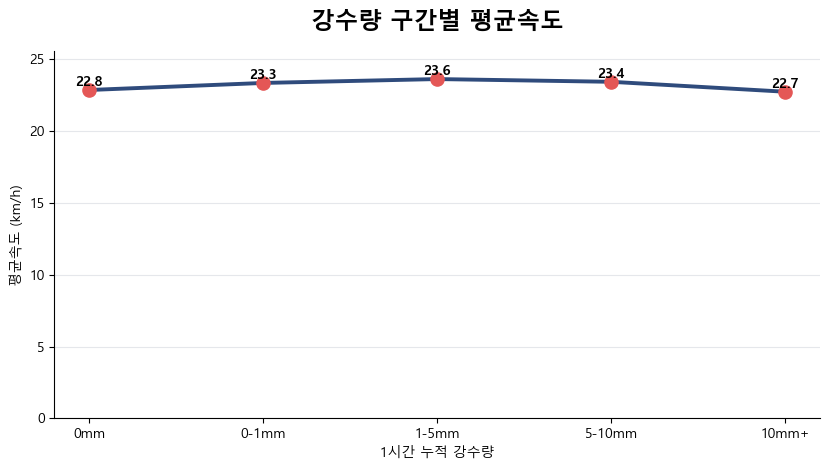

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\02_rain_intensity_speed.png


In [7]:
labels = speed_by_rain_bin["rain_bin"].tolist()

fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.plot(labels, speed_by_rain_bin["mean_speed"], color=COLORS["line"], marker="o", linewidth=2.8)
ax.scatter(labels, speed_by_rain_bin["mean_speed"], s=90, color=COLORS["rain"], zorder=3)
for x, y in zip(labels, speed_by_rain_bin["mean_speed"]):
    ax.text(x, y + 0.08, f"{y:.1f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_title("강수량 구간별 평균속도", fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("1시간 누적 강수량")
ax.set_ylabel("평균속도 (km/h)")
finish(fig, ax, "02_rain_intensity_speed.png", ylim_pad=0.08)

## 3. 경사도 구간별 평균속도

In [8]:
speed_by_abs_slope_bin = summarize(df.groupby("abs_slope_bin", observed=True))
speed_by_abs_slope_bin

,abs_slope_bin,row_count,mean_speed,median_speed,std_speed
0,0-1%,9112447,22.24,19.86,11.66
1,1-3%,2750167,23.79,20.50,13.48
2,3-5%,1173627,23.45,20.62,12.52
3,5-10%,1176790,23.59,20.86,12.59
4,10%+,881304,24.00,21.00,12.97


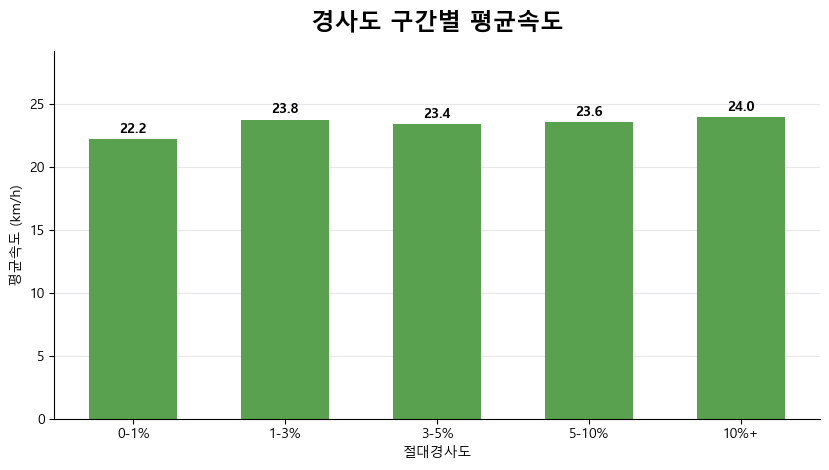

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\03_slope_bin_speed.png


In [9]:
fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.bar(speed_by_abs_slope_bin["abs_slope_bin"], speed_by_abs_slope_bin["mean_speed"], color=COLORS["bar"], width=0.58)
ax.set_title("경사도 구간별 평균속도", fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("절대경사도")
ax.set_ylabel("평균속도 (km/h)")
add_labels(ax)
finish(fig, ax, "03_slope_bin_speed.png")

## 4. 강수 x 급경사 조합별 평균속도

In [10]:
speed_by_rain_slope_group = summarize(df.groupby("rain_slope_group", observed=True))
speed_by_rain_slope_group

,rain_slope_group,row_count,mean_speed,median_speed,std_speed
0,no_rain + not_steep,9968083,22.67,20.00,12.23
1,no_rain + steep,1568152,23.75,20.88,12.80
2,rain + not_steep,3068158,22.68,20.14,11.93
3,rain + steep,489942,23.82,21.00,12.59


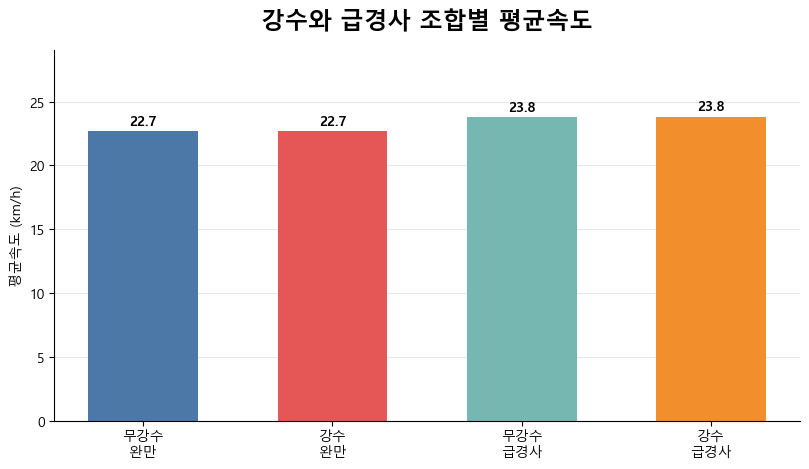

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\04_rain_slope_combo_speed.png


In [11]:
order = ["no_rain + not_steep", "rain + not_steep", "no_rain + steep", "rain + steep"]
labels = ["무강수\n완만", "강수\n완만", "무강수\n급경사", "강수\n급경사"]
plot_df = speed_by_rain_slope_group.set_index("rain_slope_group").loc[order].reset_index()

fig, ax = plt.subplots(figsize=(8.2, 4.8))
ax.bar(labels, plot_df["mean_speed"], color=["#4C78A8", "#E45756", "#76B7B2", "#F28E2B"], width=0.58)
ax.set_title("강수와 급경사 조합별 평균속도", fontsize=17, fontweight="bold", pad=16)
ax.set_ylabel("평균속도 (km/h)")
add_labels(ax)
finish(fig, ax, "04_rain_slope_combo_speed.png")

## 5. 첨두시간대별 강수 영향

T-data의 T1(오전첨두)/T2(낮)/T3(오후첨두)/N(비첨두) 4단계 대신, 우리 데이터로 재구성한 `peak_period`(N=비첨두/T1=오전첨두/T3=오후첨두 3단계, 위 1절 참고)를 씁니다.

In [12]:
speed_by_peak_rain = summarize(df.groupby(["peak_period", "rain_flag"], observed=True))
speed_by_peak_rain

,peak_period,rain_flag,row_count,mean_speed,median_speed,std_speed
0,N,no_rain,8567895,23.47,20.67,12.57
1,N,rain,2752842,23.63,21.00,12.28
2,T1,no_rain,1348485,21.90,19.57,11.61
3,T1,rain,538251,20.61,18.57,10.85
4,T3,no_rain,1619855,20.14,17.86,11.08
5,T3,rain,267007,19.20,17.21,10.39


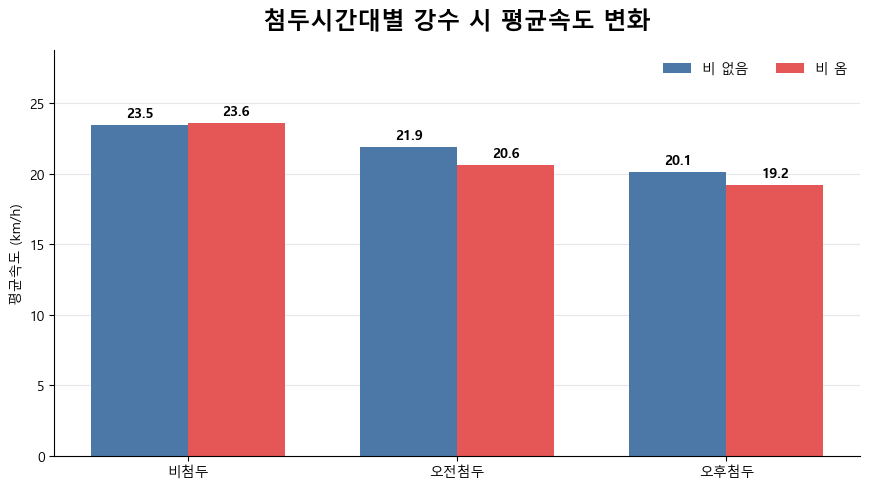

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\05_peak_rain_speed.png


In [13]:
period_col = speed_by_peak_rain.columns[0]
pivot = speed_by_peak_rain.pivot(index=period_col, columns="rain_flag", values="mean_speed").loc[["N", "T1", "T3"]]
labels = ["비첨두", "오전첨두", "오후첨두"]
x = range(len(pivot))
width = 0.36

fig, ax = plt.subplots(figsize=(8.8, 5.0))
ax.bar([i - width / 2 for i in x], pivot["no_rain"], width, label="비 없음", color=COLORS["no_rain"])
ax.bar([i + width / 2 for i in x], pivot["rain"], width, label="비 옴", color=COLORS["rain"])
ax.set_xticks(list(x), labels)
ax.set_title("첨두시간대별 강수 시 평균속도 변화", fontsize=17, fontweight="bold", pad=16)
ax.set_ylabel("평균속도 (km/h)")
ax.legend(frameon=False, ncols=2, loc="upper right")
add_labels(ax, dy=0.35)
finish(fig, ax, "05_peak_rain_speed.png")

## 6. 도로등급별 강수 영향

In [14]:
speed_by_road_rank_rain = summarize(df.groupby(["ROAD_RANK", "rain_flag"], observed=True))
speed_by_road_rank_rain

,ROAD_RANK,rain_flag,row_count,mean_speed,median_speed,std_speed
0,101,no_rain,88205,63.87,65.00,25.93
1,101,rain,26707,61.24,62.94,24.43
2,102,no_rain,351704,50.18,50.25,20.09
3,102,rain,106936,49.25,49.43,19.56
4,103,no_rain,777299,27.47,24.86,13.42
5,103,rain,237757,27.23,24.86,13.17
6,104,no_rain,10015792,21.01,19.43,9.36
7,104,rain,3095619,21.14,19.71,9.33
8,105,no_rain,31044,38.17,36.71,15.45
9,105,rain,9276,36.86,35.32,15.25


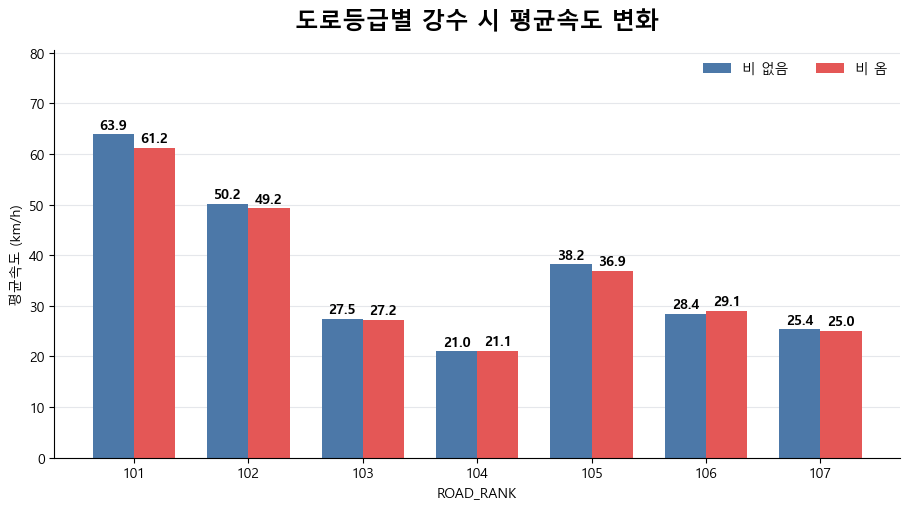

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\06_road_rank_rain_speed.png


In [15]:
pivot = speed_by_road_rank_rain.pivot(index="ROAD_RANK", columns="rain_flag", values="mean_speed").sort_index()
x = range(len(pivot))
width = 0.36

fig, ax = plt.subplots(figsize=(9.2, 5.2))
ax.bar([i - width / 2 for i in x], pivot["no_rain"], width, label="비 없음", color=COLORS["no_rain"])
ax.bar([i + width / 2 for i in x], pivot["rain"], width, label="비 옴", color=COLORS["rain"])
ax.set_xticks(list(x), [str(v) for v in pivot.index])
ax.set_title("도로등급별 강수 시 평균속도 변화", fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("ROAD_RANK")
ax.set_ylabel("평균속도 (km/h)")
ax.legend(frameon=False, ncols=2, loc="upper right")
add_labels(ax, dy=0.55)
finish(fig, ax, "06_road_rank_rain_speed.png", ylim_pad=0.2)

## 7. 보조 테이블 및 변수 상관관계

경사방향(오르막/내리막/평지)별, 도로등급×경사구간별 평균속도와, 평균속도와 다른 변수들의 상관관계를 확인합니다.

In [16]:
speed_by_slope_direction = summarize(df.groupby("slope_direction", observed=True))
speed_by_slope_direction

,slope_direction,row_count,mean_speed,median_speed,std_speed
0,downhill,2969702,23.41,20.29,13.11
1,flat,9112447,22.24,19.86,11.66
2,uphill,3012186,24.02,21.00,12.98


In [17]:
speed_by_road_rank_slope = summarize(df.groupby(["ROAD_RANK", "abs_slope_bin"], observed=True))
speed_by_road_rank_slope

,ROAD_RANK,abs_slope_bin,row_count,mean_speed,median_speed,std_speed
0,101,0-1%,46368,61.26,64.38,25.79
1,101,1-3%,38976,60.49,59.21,25.22
2,101,3-5%,9408,56.66,56.00,24.72
3,101,5-10%,12096,73.10,80.13,23.16
4,101,10%+,8064,81.02,86.62,19.09
5,102,0-1%,258384,50.91,51.39,20.47
6,102,1-3%,114912,47.26,47.38,18.83
7,102,3-5%,37632,50.84,51.00,18.28
8,102,5-10%,28224,48.24,47.98,19.72
9,102,10%+,19488,54.30,58.70,21.28


In [18]:
corr_cols = ["평균속도", "precip_mm", "abs_slope_pct", "slope_pct", "elev_mean_m", "elev_delta_m", "MAX_SPD", "LENGTH"]
speed_feature_correlations = df[corr_cols].corr(numeric_only=True)["평균속도"].sort_values(ascending=False).reset_index()
speed_feature_correlations.columns = ["feature", "corr_with_avg_speed"]
speed_feature_correlations["corr_with_avg_speed"] = speed_feature_correlations["corr_with_avg_speed"].round(4)
speed_feature_correlations

,feature,corr_with_avg_speed
0,평균속도,1.0000
1,LENGTH,0.4318
2,MAX_SPD,0.4140
3,elev_mean_m,0.0753
4,abs_slope_pct,0.0237
5,elev_delta_m,0.0129
6,slope_pct,0.0087
7,precip_mm,-0.0033


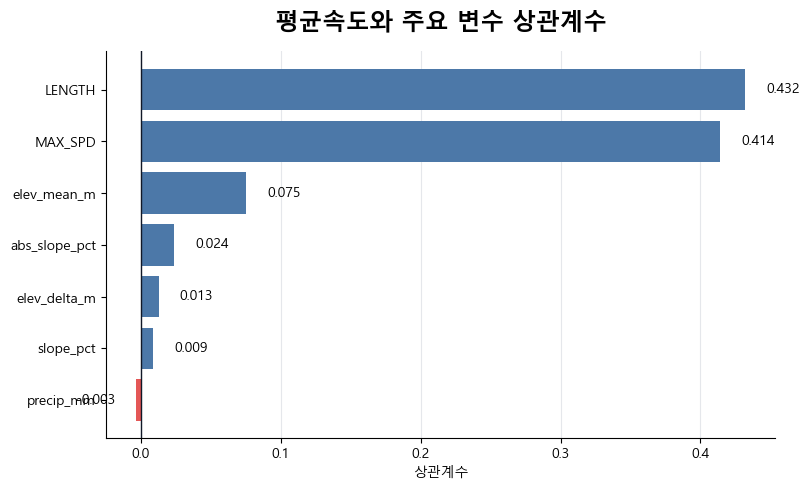

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\eda\07_feature_correlation_speed.png


In [19]:
plot_df = speed_feature_correlations[speed_feature_correlations["feature"] != "평균속도"].copy()
plot_df = plot_df.sort_values("corr_with_avg_speed")
colors = ["#E45756" if v < 0 else "#4C78A8" for v in plot_df["corr_with_avg_speed"]]

fig, ax = plt.subplots(figsize=(8.2, 5.0))
ax.barh(plot_df["feature"], plot_df["corr_with_avg_speed"], color=colors)
ax.axvline(0, color="#111827", linewidth=1)
ax.set_title("평균속도와 주요 변수 상관계수", fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("상관계수")
for patch in ax.patches:
    width = patch.get_width()
    x = width + (0.015 if width >= 0 else -0.015)
    ha = "left" if width >= 0 else "right"
    ax.text(x, patch.get_y() + patch.get_height() / 2, f"{width:.3f}", va="center", ha=ha, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "07_feature_correlation_speed.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "07_feature_correlation_speed.png")

## 요약

In [20]:
no_rain_speed = speed_by_rain_flag.set_index("rain_flag").loc["no_rain", "mean_speed"]
rain_speed = speed_by_rain_flag.set_index("rain_flag").loc["rain", "mean_speed"]
no_rain_flat = speed_by_rain_slope_group.set_index("rain_slope_group").loc["no_rain + not_steep", "mean_speed"]
rain_steep = speed_by_rain_slope_group.set_index("rain_slope_group").loc["rain + steep", "mean_speed"]
peak_pivot = speed_by_peak_rain.pivot(index=speed_by_peak_rain.columns[0], columns="rain_flag", values="mean_speed")
t1_no_rain = peak_pivot.loc["T1", "no_rain"]
t1_rain = peak_pivot.loc["T1", "rain"]

print(f"무강수 평균속도: {no_rain_speed:.2f} km/h")
print(f"강수 평균속도: {rain_speed:.2f} km/h")
print(f"무강수 + 완만 구간 평균속도: {no_rain_flat:.2f} km/h")
print(f"강수 + 급경사 구간 평균속도: {rain_steep:.2f} km/h")
print(f"오전첨두 무강수 평균속도: {t1_no_rain:.2f} km/h")
print(f"오전첨두 강수 평균속도: {t1_rain:.2f} km/h")

무강수 평균속도: 22.82 km/h
강수 평균속도: 22.84 km/h
무강수 + 완만 구간 평균속도: 22.67 km/h
강수 + 급경사 구간 평균속도: 23.82 km/h
오전첨두 무강수 평균속도: 21.90 km/h
오전첨두 강수 평균속도: 20.61 km/h


이 결과는 인과관계 검증이 아니라 탐색적 분석입니다. 최종 해석에서는 시간대·도로등급·제한속도·링크별 특성을 함께 통제해야 합니다.

**12번 노트북(예측모델)과의 교차검증**: 모델 쪽에서는 강수 관련 파생피처 8개의 gain이 5차례 연속 0에 가까웠고(이웃속도 피처가 정보를 이미 흡수), 별도 에너지-피처 상관분석에서도 강수의 상관계수가 0.001~0.002로 거의 0이었습니다. 위 상관표에서 `precip_mm`의 원본 상관계수가 몇인지 확인하면, "모델 gain이 낮은 이유가 정말 원본 신호 자체가 약해서인지" 검증할 수 있습니다.